# Writer-Adaptive Cohort-Margin Calibration for One-Class Signature Verification
### Experiment v5 — intensity-normalised protocol, development partition

This experiment evaluates a writer-adaptive calibration procedure for one-class
support vector machine signature verification operating in a pairwise dissimilarity
representation. Three conditions are compared under an identical protocol: a fixed
global hyperparameter setting, target-based per-writer calibration, and
cohort-margin per-writer calibration. A decision-attribution component is evaluated
separately for faithfulness.

**Acquisition-cue control.** A preceding audit (v4.5) established that in CEDAR the
mean grey level of the original scan separates genuine signatures from forgeries of
the same writer with a per-writer AUC of 1.0000, with zero within-writer overlap in
all 25 development writers and consistent direction (forgeries lighter), at
p = 1.1e-130 pooled. The separation is present in the unprocessed files and is
therefore a property of the dataset rather than of the preprocessing pipeline.
Because any intensity-sensitive feature can exploit this cue, all primary results
in this experiment are computed on **intensity-normalised** images. The unnormalised
grayscale condition is retained solely to quantify the magnitude of the cue's
contribution.

**Partitioning.** The 55 writers are divided into 25 development and 30
confirmation writers under a fixed seed. All design decisions, diagnostics and
hyperparameter grids in this experiment are determined on development writers only.
Confirmation writers are not read anywhere in this notebook.

**Hypotheses.** For median per-writer false rejection rate, with a two-tailed paired
Wilcoxon signed-rank test at α = 0.05 across development writers:

- H₀: per-writer calibration produces no difference in median FRR relative to a
  fixed global hyperparameter setting.
- H₁: per-writer calibration produces a difference in median FRR.

A secondary, directional check is applied to per-writer AUC, where the null of no
change is the desired outcome: a reduction in FRR accompanied by a significant loss
of AUC would indicate the boundary had merely been loosened rather than relocated.

**Environment.** Google Colaboratory, High-RAM, CPU. `OneClassSVM` is a CPU-only
estimator with no GPU or TPU backend; selecting an accelerator confers no benefit.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import numpy as np, pandas as pd, itertools, random, time, sys, platform
from PIL import Image, ImageOps
from math import floor, ceil, sqrt
from skimage.feature import hog
from skimage.filters import threshold_otsu
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr, wilcoxon
import matplotlib.pyplot as plt
from pathlib import Path

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED); random.seed(RANDOM_SEED)

NB_T0 = time.time(); SECTION_TIMES = {}
def mark(section):
    now = time.time(); prev = SECTION_TIMES.get("_last", NB_T0)
    SECTION_TIMES[section] = now - prev; SECTION_TIMES["_last"] = now
    print(f"[timer] {section}: {now-prev:.1f}s   (total {now-NB_T0:.1f}s)", flush=True)

_trapz = getattr(np, "trapezoid", None) or np.trapz   # np.trapz removed in NumPy 2

print(f"Python {sys.version.split()[0]} | {platform.machine()} | numpy {np.__version__}")
print("Estimator: sklearn OneClassSVM (CPU-only)")

Python 3.13.16 | x86_64 | numpy 2.1.3
Estimator: sklearn OneClassSVM (CPU-only)


In [ ]:
DATASET_DIR = Path("/content/drive/MyDrive/cedar-dataset/signatures")
GENUINE_DIR = DATASET_DIR/"full_org"; FORGED_DIR = DATASET_DIR/"full_forg"
CACHE_DIR = Path("/content/drive/MyDrive/4buwan_cache"); CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("/content/drive/MyDrive/4buwan_results_v5"); OUT_DIR.mkdir(parents=True, exist_ok=True)
USE_CACHE = True

# --- preprocessing (unchanged from the original experiment) ---
IMG_SIZE = (100,100); MAX_CROP_ASPECT = 2.5; DENSITY_FRAC = 0.05
N_WRITERS = 55; N_TRAIN_GENUINE = 12

# --- intensity normalisation ---
INK_THRESH  = 0.2     # ink definition for the normalisation statistic
TARGET_INK  = 0.60    # every image is rescaled to this mean ink intensity

# --- writer partition (fixed; must match v4 and v4.5) ---
SPLIT_SEED = 20261014; N_DEV = 25

# --- representation and descriptor ---
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8,8), cells_per_block=(2,2), block_norm="L2-Hys")
N_BANDS = 8           # band layout retained: v4 showed it outperforms a 3x3 region grid

# --- fixed baseline (pre-specified, not tuned) ---
PAIR_BASELINE = {"nu": 0.10, "gamma": "scale"}

# --- calibration ---
NU_GRID = (0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30)
GAMMA_MULTIPLIERS = (0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0)
TARGET_ACCEPT = 0.70          # target-based variant, pre-specified
TARGET_COHORT_REJECT = 0.95
COHORT_SIZE = 20              # surrogate impostors drawn from the cohort pool
HARD_COHORT = True            # select nearest writers rather than at random

# --- attribution ---
ATTR_PATCH = 12; ATTR_STRIDE = 6; ATTR_N_GENUINE = 3; ATTR_N_FORGED = 3
DELETION_STEPS = 10; DELETION_RANDOM_REPEATS = 5
SATURATION_TOL = 1e-9   # below this, occluding any patch leaves the score unchanged

print("Configuration set.")

Configuration set.


## 1. Data and writer partition

Each writer contributes 24 genuine and 24 forged signatures. Twelve genuine
signatures form the enrolment set; the remaining twelve genuine signatures and all
twenty-four forgeries are held out for evaluation. No forged signature is used at
any point during enrolment, calibration or model fitting.

In [4]:
genuine_files = sorted(GENUINE_DIR.glob("*.png")); forged_files = sorted(FORGED_DIR.glob("*.png"))
def get_writer_id(fp): return int(Path(fp).stem.split("_")[1])
assert len(genuine_files)==1320 and len(forged_files)==1320

rng_split = random.Random(RANDOM_SEED); writer_splits = {}
for wid in range(1, N_WRITERS+1):
    g = sorted([p for p in genuine_files if get_writer_id(p)==wid])
    f = sorted([p for p in forged_files  if get_writer_id(p)==wid])
    sg = g.copy(); rng_split.shuffle(sg); sf = f.copy(); rng_split.shuffle(sf)
    writer_splits[wid] = {"train_genuine": sg[:N_TRAIN_GENUINE],
                          "test_genuine":  sg[N_TRAIN_GENUINE:], "test_forged": sf}

_perm = np.random.default_rng(SPLIT_SEED).permutation(np.arange(1, N_WRITERS+1))
DEV = sorted(int(w) for w in _perm[:N_DEV]); CONFIRM = sorted(int(w) for w in _perm[N_DEV:])
assert DEV == [3,8,9,10,12,17,19,21,22,23,28,29,34,36,39,40,42,43,44,47,49,50,51,52,55]

SPLIT_KEYS = [("train","train_genuine"), ("test_gen","test_genuine"), ("test_for","test_forged")]
FILES = {k: [p for w in range(1, N_WRITERS+1) for p in writer_splits[w][src]] for k, src in SPLIT_KEYS}
def _rows(key, writers):
    s = set(writers); return np.array([i for i,p in enumerate(FILES[key]) if get_writer_id(p) in s], int)

print(f"Development  ({len(DEV)}): {DEV}")
print(f"Confirmation ({len(CONFIRM)}): held in reserve, not evaluated in this notebook")
print(f"Per writer: {N_TRAIN_GENUINE} enrolled genuine, "
      f"{24-N_TRAIN_GENUINE} held-out genuine, 24 forged")
mark("1 partition")

Development  (25): [3, 8, 9, 10, 12, 17, 19, 21, 22, 23, 28, 29, 34, 36, 39, 40, 42, 43, 44, 47, 49, 50, 51, 52, 55]
Confirmation (30): held in reserve, not evaluated in this notebook
Per writer: 12 enrolled genuine, 12 held-out genuine, 24 forged
[timer] 1 partition: 7.1s   (total 7.1s)


## 2. Preprocessing and intensity normalisation

Geometric preprocessing is unchanged: inversion to an ink-bright representation,
Otsu-based identification of ink, a density-filtered bounding-box crop, padding to
an aspect ratio of at most 2.5, and resizing onto a 100×100 canvas.

Two input conditions are then produced from each preprocessed image.

**Unnormalised (`gray`).** The preprocessed image as previously used. Retained only
to quantify the contribution of the acquisition cue.

**Intensity-normalised (`norm`).** The mean intensity of ink pixels is computed and
the image is rescaled so that this mean equals a fixed constant for every image,
then clipped to the unit interval. The transformation is monotone and preserves the
relative intensity structure within an image — including stroke-weight variation
along a pen trace — while removing the global intensity level that the audit
identified as separating genuine from forged scans. Normalisation is applied after
geometric preprocessing so that the ink statistic is computed over the signature
region rather than over surrounding whitespace.

Binarisation would also remove the cue, but discards within-image intensity
variation that is plausibly writer-specific. Rescaling is the weaker intervention
and is therefore preferred.

In [5]:
def _common_geometry(img, max_aspect=MAX_CROP_ASPECT, density_frac=DENSITY_FRAC, img_size=IMG_SIZE):
    tw, th = img_size
    ink = img > threshold_otsu(img) if img.max() > img.min() else np.zeros_like(img, bool)
    if ink.any():
        rc, cc = ink.sum(1), ink.sum(0)
        sr = rc >= max(2, rc.max()*density_frac); sc = cc >= max(2, cc.max()*density_frac)
        if sr.any() and sc.any():
            t,b = np.where(sr)[0][[0,-1]]; l,r = np.where(sc)[0][[0,-1]]
            img = img[t:b+1, l:r+1]
    h,w = img.shape
    if w/h > max_aspect:
        pad = max(0, ceil(w/max_aspect)-h); img = np.pad(img, ((pad//2, pad-pad//2),(0,0)), constant_values=0)
    elif h/w > max_aspect:
        pad = max(0, ceil(h/max_aspect)-w); img = np.pad(img, ((0,0),(pad//2, pad-pad//2)), constant_values=0)
    h,w = img.shape
    nw = min(tw, max(1, w*th//h)); nh = max(1, h*nw//w)
    img = np.asarray(Image.fromarray(img.astype(np.uint8)).resize((nw,nh)))
    top=floor((th-nh)/2); bot=ceil((th-nh)/2); lef=floor((tw-nw)/2); rig=ceil((tw-nw)/2)
    return np.pad(img, ((top,bot),(lef,rig)), mode="constant", constant_values=0)

def preprocess_gray(path):
    with Image.open(path) as im:
        return _common_geometry(np.asarray(ImageOps.invert(im.convert("L")))).astype(np.float32)/255.0

def intensity_normalise(i01, thr=INK_THRESH, target=TARGET_INK):
    """Rescale so mean ink intensity equals `target`, removing the global level."""
    ink = i01 > thr
    if not ink.any(): return i01.copy()
    m = float(i01[ink].mean())
    if m <= 1e-8: return i01.copy()
    return np.clip(i01 * (target/m), 0.0, 1.0).astype(np.float32)

def raw_feature_fn(i01): return i01.flatten()
def hog_feature_fn(i01): return hog(i01, **HOG_PARAMS)
FEATURE_FNS = {"RAW": raw_feature_fn, "HOG": hog_feature_fn}

GEOM_NAMES = ["ink_total","ink_area","cent_y","cent_x","spread_y","spread_x",
              "bbox_aspect","mean_ink_intensity","fill_density"]
def geom_stats(i01, thr=INK_THRESH):
    ink = i01 > thr
    tot = float(i01.sum()); area = float(ink.sum())
    ys, xs = np.nonzero(ink)
    if len(ys)==0: return np.zeros(len(GEOM_NAMES))
    h = float(ys.max()-ys.min()+1); w = float(xs.max()-xs.min()+1)
    return np.array([tot, area, float(ys.mean()), float(xs.mean()), float(ys.std()),
                     float(xs.std()), w/max(h,1.0), tot/max(area,1.0), tot/max(h*w,1.0)])

print("Preprocessing and normalisation defined.")

Preprocessing and normalisation defined.


In [6]:
def _extract(paths):
    out = {("RAW","gray"):[], ("HOG","gray"):[], ("RAW","norm"):[], ("HOG","norm"):[],
           ("GEO","gray"):[], ("GEO","norm"):[]}
    for k, p in enumerate(paths):
        g = preprocess_gray(p); n = intensity_normalise(g)
        for cond, im in (("gray", g), ("norm", n)):
            out[("RAW",cond)].append(raw_feature_fn(im))
            out[("HOG",cond)].append(hog_feature_fn(im))
            out[("GEO",cond)].append(geom_stats(im))
        if (k+1) % 400 == 0: print(f"    ...{k+1}/{len(paths)}", flush=True)
    return {kk: np.asarray(v, dtype=np.float32) for kk, v in out.items()}

F = {}
for key in FILES:
    names = {kk: CACHE_DIR/f"v5_{kk[0]}_{kk[1]}_{key}.npy"
             for kk in [("RAW","gray"),("HOG","gray"),("RAW","norm"),("HOG","norm"),
                        ("GEO","gray"),("GEO","norm")]}
    if USE_CACHE and all(f.exists() for f in names.values()):
        for kk, f in names.items(): F[(*kk, key)] = np.load(f)
        print(f"  {key}: loaded from cache")
    else:
        print(f"  {key}: extracting {len(FILES[key])} images (two conditions)...", flush=True)
        got = _extract(FILES[key])
        for kk, arr in got.items(): np.save(names[kk], arr); F[(*kk, key)] = arr
        print(f"  {key}: cached  RAW {got[('RAW','gray')].shape}  HOG {got[('HOG','gray')].shape}")

HOG_NB = int(round(sqrt(F[("HOG","gray","train")].shape[1]/36)))
assert HOG_NB*HOG_NB*36 == F[("HOG","gray","train")].shape[1]
print(f"\nHOG block grid: {HOG_NB}x{HOG_NB}x36 = {HOG_NB*HOG_NB*36}")
mark("2 features")

  train: extracting 660 images (two conditions)...
    ...400/660
  train: cached  RAW (660, 10000)  HOG (660, 4356)
  test_gen: extracting 660 images (two conditions)...
    ...400/660
  test_gen: cached  RAW (660, 10000)  HOG (660, 4356)
  test_for: extracting 1320 images (two conditions)...
    ...400/1320
    ...800/1320
    ...1200/1320
  test_for: cached  RAW (1320, 10000)  HOG (1320, 4356)

HOG block grid: 11x11x36 = 4356
[timer] 2 features: 1240.3s   (total 1247.4s)


## 3. Verification that normalisation removes the acquisition cue

Before the normalised condition is used for any result, the cue it is intended to
remove is measured in both conditions. The nine image statistics from the audit are
evaluated on held-out signatures and summarised as mean per-writer, sign-free AUC.

The normalisation is accepted only if the strongest statistic falls from
approximately 1.0 in the unnormalised condition to a level consistent with weak or
incidental separation. Should the cue survive, the remaining results in this
notebook would still be confounded and the normalisation would require revision
before they could be interpreted.

In [7]:
def _per_writer_auc(mat_tg, mat_tf, writers, key_tg="test_gen", key_tf="test_for"):
    """mat_*: full-corpus matrices. Returns sign-free per-writer AUC per column."""
    res = []
    for wid in writers:
        g = mat_tg[_rows(key_tg, [wid])]; f = mat_tf[_rows(key_tf, [wid])]
        y = np.r_[np.ones(len(g)), np.zeros(len(f))]
        row = []
        for c in range(g.shape[1]):
            v = np.r_[g[:, c], f[:, c]]
            if np.allclose(v, v[0]): row.append(0.5); continue
            a = roc_auc_score(y, v); row.append(max(a, 1-a))
        res.append(row)
    return np.mean(res, axis=0)

cue = pd.DataFrame({cond: _per_writer_auc(F[("GEO",cond,"test_gen")], F[("GEO",cond,"test_for")], DEV)
                    for cond in ("gray","norm")}, index=GEOM_NAMES)
cue["delta"] = cue["norm"] - cue["gray"]

print("="*74); print("ACQUISITION-CUE STRENGTH BY INPUT CONDITION"); print("="*74)
print("mean per-writer sign-free AUC of each image statistic (held-out signatures)\n")
print(cue.round(4).to_string())
cue.to_csv(OUT_DIR/"cue_strength_by_condition.csv")

g_max = float(cue["gray"].max()); n_max = float(cue["norm"].max())
print(f"\n  strongest cue, gray : {cue['gray'].idxmax():20s} AUC {g_max:.4f}")
print(f"  strongest cue, norm : {cue['norm'].idxmax():20s} AUC {n_max:.4f}")
print(f"  reduction           : {g_max - n_max:+.4f}")

print("\n" + "-"*74)
if n_max < 0.75:
    print("  NORMALISATION ACCEPTED -- the acquisition cue no longer supports reliable")
    print("  separation. Primary results below are computed on the normalised condition.")
elif n_max < 0.85:
    print("  NORMALISATION PARTIAL -- a residual cue remains. Primary results proceed on")
    print("  the normalised condition, and the residual is reported as a limitation.")
else:
    print("  NORMALISATION INSUFFICIENT -- the cue survives rescaling. Results below remain")
    print("  confounded; binarisation should be evaluated before they are interpreted.")
mark("3 cue verification")

ACQUISITION-CUE STRENGTH BY INPUT CONDITION
mean per-writer sign-free AUC of each image statistic (held-out signatures)

                      gray    norm   delta
ink_total           0.9913  0.9969  0.0057
ink_area            0.7844  0.8218  0.0374
cent_y              0.7467  0.7478  0.0011
cent_x              0.6369  0.6504  0.0135
spread_y            0.8014  0.8256  0.0242
spread_x            0.7233  0.7536  0.0303
bbox_aspect         0.8212  0.8248  0.0036
mean_ink_intensity  0.9401  0.9997  0.0596
fill_density        0.9993  1.0000  0.0007

  strongest cue, gray : fill_density         AUC 0.9993
  strongest cue, norm : fill_density         AUC 1.0000
  reduction           : -0.0007

--------------------------------------------------------------------------
  NORMALISATION INSUFFICIENT -- the cue survives rescaling. Results below remain
  confounded; binarisation should be evaluated before they are interpreted.
[timer] 3 cue verification: 1.0s   (total 1248.3s)


## 4. Feature standardisation and pairwise dissimilarity representation

A single `StandardScaler` per representation and condition is fitted on the
enrolled genuine signatures of development writers only, then frozen. Fitting the
scaler before computing dissimilarity measures ensures that cosine, correlation,
Euclidean and histogram-based terms are not dominated by whichever feature
dimensions carry the largest raw variance.

A questioned signature is compared against an enrolled signature through a
seventeen-dimensional symmetric descriptor: eight global similarity measures
(cosine, Pearson, Spearman, normalised Euclidean, mean absolute difference and its
dispersion, histogram intersection, chi-square) and nine band-wise correlations
obtained by partitioning the feature vector into contiguous segments.

The representation addresses a sample-size constraint rather than a feature-quality
one. Twelve enrolled signatures in a 4,356-dimensional feature space provide
0.003 samples per dimension; the same twelve signatures yield C(12,2) = 66 pairs in
seventeen dimensions, or 3.9 samples per dimension. The pairwise framing follows the
distance-statistics formulation used in the original CEDAR study and the rank-
correlation pair representation used in subsequent one-class work on the same
dataset.

In [8]:
SC, FS = {}, {}
dev_tr = _rows("train", DEV)
for rep in ("RAW","HOG"):
    for cond in ("gray","norm"):
        sc = StandardScaler().fit(F[(rep,cond,"train")][dev_tr].astype(np.float64))
        SC[(rep,cond)] = sc
        for key in ("train","test_gen","test_for"):
            FS[(rep,cond,key)] = sc.transform(F[(rep,cond,key)].astype(np.float64)).astype(np.float32)
print(f"Scalers fitted on {len(dev_tr)} enrolled genuine signatures from {len(DEV)} development writers.")

EPS = 1e-12
GLOBAL_NAMES = ["cos","pearson","spearman","eucn","mad","mad_sd","intersect","chi2"]
DESC_NAMES = GLOBAL_NAMES + [f"band{i}" for i in range(N_BANDS)] + ["band_mean"]

def _corr(x, y):
    x = x - x.mean(); y = y - y.mean()
    return float(x @ y / (np.linalg.norm(x)*np.linalg.norm(y) + EPS))

def pair_descriptor(a, b):
    a = np.asarray(a, np.float64); b = np.asarray(b, np.float64)
    out = []
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    out.append(float(a @ b / (na*nb + EPS)))
    am, bm = a - a.mean(), b - b.mean()
    out.append(float(am @ bm / (np.linalg.norm(am)*np.linalg.norm(bm) + EPS)))
    rho = spearmanr(a, b).correlation
    out.append(float(rho) if np.isfinite(rho) else 0.0)
    out.append(float(np.linalg.norm(a-b) / (na + nb + EPS)))
    d = np.abs(a-b); out.append(float(d.mean())); out.append(float(d.std()))
    ap, bp = np.clip(a,0,None), np.clip(b,0,None)
    ap = ap/(ap.sum()+EPS); bp = bp/(bp.sum()+EPS)
    out.append(float(np.minimum(ap,bp).sum()))
    out.append(float(0.5*((ap-bp)**2/(ap+bp+EPS)).sum()))
    bands = [_corr(x, y) for x, y in zip(np.array_split(a, N_BANDS), np.array_split(b, N_BANDS))]
    out.extend(bands); out.append(float(np.mean(bands)))
    return np.array(out)

PAIR_DIM = len(DESC_NAMES)
assert len(pair_descriptor(np.random.rand(500), np.random.rand(500))) == PAIR_DIM
print(f"Pair descriptor: {PAIR_DIM} dimensions")
print(f"  samples per dimension: {66/PAIR_DIM:.1f} (pairwise) vs {12/4356:.4f} (feature space, HOG)")

Scalers fitted on 300 enrolled genuine signatures from 25 development writers.
Pair descriptor: 17 dimensions
  samples per dimension: 3.9 (pairwise) vs 0.0028 (feature space, HOG)


In [9]:
def build_descsets(rep, cond, writers=DEV, verbose=True):
    Xtr, Xtg, Xtf = (FS[(rep,cond,k)] for k in ("train","test_gen","test_for"))
    store = {}
    for n, wid in enumerate(writers, 1):
        W  = Xtr[_rows("train",[wid])].astype(np.float64)
        Tg = Xtg[_rows("test_gen",[wid])].astype(np.float64)
        Tf = Xtf[_rows("test_for",[wid])].astype(np.float64)
        idx = list(itertools.combinations(range(len(W)), 2))
        store[wid] = {"W": W, "idx": idx,
                      "D":  np.array([pair_descriptor(W[i], W[j]) for i,j in idx]),
                      "Qg": np.array([[pair_descriptor(q,t) for t in W] for q in Tg]),
                      "Qf": np.array([[pair_descriptor(q,t) for t in W] for q in Tf])}
        if verbose and n % 5 == 0: print(f"    ...{n}/{len(writers)}", flush=True)
    return store

ARMS = [("HOG","norm"), ("RAW","norm"), ("HOG","gray"), ("RAW","gray")]
DS = {}
for a in ARMS:
    t0 = time.time(); print(f"Descriptors for {a[0]}-{a[1]} ...", flush=True)
    DS[a] = build_descsets(*a); print(f"  {time.time()-t0:.0f}s", flush=True)
mark("4 descriptors")

Descriptors for HOG-norm ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  20s
Descriptors for RAW-norm ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  32s
Descriptors for HOG-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  20s
Descriptors for RAW-gray ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  32s
[timer] 4 descriptors: 103.8s   (total 1352.2s)


## 5. Verification protocol and fixed baseline

A one-class support vector machine with a radial basis function kernel is fitted
per writer on that writer's 66 enrolled pairs, standardised by a scaler fitted on
those pairs alone. A questioned signature is paired with each of the twelve enrolled
signatures and the decision is taken by majority vote over the twelve resulting pair
classifications. The threshold-free score used for AUC is the mean decision function
across the same twelve pairs.

AUC is computed per writer and then averaged. Pooling scores across writers would
conflate per-writer decision-function scales and is not appropriate for a
writer-dependent system.

The fixed baseline uses ν = 0.10 and the `scale` heuristic for γ, both specified in
advance and held constant across all writers and arms.

In [10]:
def _decide(p): return 1 if int((p==1).sum()) > len(p)/2 else -1

def fit_pairs(D, nu, gamma):
    sc = StandardScaler().fit(D)
    return OneClassSVM(kernel="rbf", nu=nu, gamma=gamma).fit(sc.transform(D)), sc

def _score_block(m, sc, Q):
    dec, sco = [], []
    for q in Q:
        Qs = sc.transform(q)
        dec.append(_decide(m.predict(Qs))); sco.append(float(m.decision_function(Qs).mean()))
    return np.array(dec), np.array(sco)

def evaluate(arm, params, label=""):
    """params: {'nu','gamma'} applied to all writers, or {wid: {'nu','gamma'}}."""
    store, rows = DS[arm], []
    for wid in DEV:
        s = store[wid]
        pr = params[wid] if wid in params else params
        m, sc = fit_pairs(s["D"], pr["nu"], pr["gamma"])
        gd, gs = _score_block(m, sc, s["Qg"]); fd, fs = _score_block(m, sc, s["Qf"])
        tp=int((gd==1).sum()); fn=int((gd==-1).sum()); fp=int((fd==1).sum()); tn=int((fd==-1).sum())
        frr=fn/(tp+fn); far=fp/(fp+tn)
        prec = tp/(tp+fp) if (tp+fp) else 0.0; rec = tp/(tp+fn) if (tp+fn) else 0.0
        rows.append({"Writer":wid, "nu":pr["nu"], "gamma":pr["gamma"], "FRR":frr, "FAR":far,
                     "Accuracy":(tp+tn)/(tp+tn+fp+fn),
                     "F1": 2*prec*rec/(prec+rec) if (prec+rec) else 0.0,
                     "AUC": roc_auc_score(np.r_[np.ones(len(gs)), np.zeros(len(fs))], np.r_[gs,fs]),
                     "BalAcc": ((1-frr)+(1-far))/2})
    df = pd.DataFrame(rows)
    ov = {"Label": label, **{k: float(df[k].mean()) for k in
          ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
          "median_FRR": float(df.FRR.median())}
    return df, ov

base_df, base_ov = {}, []
for a in ARMS:
    d, o = evaluate(a, PAIR_BASELINE, f"fixed / {a[0]}-{a[1]}")
    base_df[a] = d; base_ov.append({**o, "Rep":a[0], "Condition":a[1]})
    print(f"  {a[0]}-{a[1]:5s}  BalAcc {o['BalAcc']:.4f}  AUC {o['AUC']:.4f}  "
          f"FRR {o['FRR']:.4f}  FAR {o['FAR']:.4f}")

BASE = pd.DataFrame(base_ov)
print("\n" + "="*96); print("FIXED BASELINE -- 25 development writers, nu=0.10, gamma=scale"); print("="*96)
print(BASE[["Rep","Condition","FRR","FAR","Accuracy","F1","AUC","BalAcc","median_FRR"]]
      .round(4).to_string(index=False))
BASE.to_csv(OUT_DIR/"fixed_baseline.csv", index=False)

print("\n" + "="*96); print("CONTRIBUTION OF THE ACQUISITION CUE (gray minus norm, fixed baseline)"); print("="*96)
for rep in ("RAW","HOG"):
    gl = BASE[(BASE.Rep==rep)&(BASE.Condition=="gray")].iloc[0]
    nm = BASE[(BASE.Rep==rep)&(BASE.Condition=="norm")].iloc[0]
    print(f"  {rep}: AUC {gl.AUC:.4f} -> {nm.AUC:.4f} ({nm.AUC-gl.AUC:+.4f})   "
          f"BalAcc {gl.BalAcc:.4f} -> {nm.BalAcc:.4f} ({nm.BalAcc-gl.BalAcc:+.4f})")
mark("5 fixed baseline")

  HOG-norm   BalAcc 0.8008  AUC 0.8868  FRR 0.2700  FAR 0.1283
  RAW-norm   BalAcc 0.8217  AUC 0.9701  FRR 0.3467  FAR 0.0100
  HOG-gray   BalAcc 0.8017  AUC 0.8871  FRR 0.2700  FAR 0.1267
  RAW-gray   BalAcc 0.8092  AUC 0.9762  FRR 0.3767  FAR 0.0050

FIXED BASELINE -- 25 development writers, nu=0.10, gamma=scale
Rep Condition    FRR    FAR  Accuracy     F1    AUC  BalAcc  median_FRR
HOG      norm 0.2700 0.1283    0.8244 0.7582 0.8868  0.8008      0.2500
RAW      norm 0.3467 0.0100    0.8778 0.7662 0.9701  0.8217      0.3333
HOG      gray 0.2700 0.1267    0.8256 0.7598 0.8871  0.8017      0.2500
RAW      gray 0.3767 0.0050    0.8711 0.7503 0.9762  0.8092      0.4167

CONTRIBUTION OF THE ACQUISITION CUE (gray minus norm, fixed baseline)
  RAW: AUC 0.9762 -> 0.9701 (-0.0061)   BalAcc 0.8092 -> 0.8217 (+0.0125)
  HOG: AUC 0.8871 -> 0.8868 (-0.0003)   BalAcc 0.8017 -> 0.8008 (-0.0008)
[timer] 5 fixed baseline: 2.0s   (total 1354.1s)


## 6. Writer-adaptive calibration

Two quantities are estimated for each writer from genuine data alone.

**Leave-one-signature-out acceptance.** For each of the twelve enrolled
signatures in turn, the model is fitted on the 55 pairs that do not involve that
signature and the held-out signature is then verified using the 11 pairs that do.
The resulting acceptance rate estimates the probability that an unseen genuine
signature from this writer would be accepted, that is 1 − FRR, without reference to
any held-out or forged sample. Leaving out a signature rather than a pair is
necessary: removing a single pair would leave the held-out signature present in
other training pairs.

**Cohort acceptance.** Genuine signatures belonging to other writers are presented
to the model as surrogate impostors. These are legitimately available at enrolment
in any institutional setting that holds specimens for multiple account holders, so
the genuine-only constraint is preserved. The cohort is drawn from the enrolment
sets of development writers only, which also means that confirmation writers can
later be calibrated without any confirmation-writer data entering another writer's
calibration.

**Cohort hardness.** Randomly chosen cohort writers are easily rejected, so the
cohort term saturates and exerts little pressure on the boundary. The cohort here
is instead composed of the writers whose enrolled signatures are most similar to
those of the writer being calibrated, measured by cosine similarity between mean
enrolled feature vectors. This yields a cohort that constrains the boundary where
it matters.

**Selection criteria.** Two are compared.

- *Target-based* (the previous design): among candidates meeting a fixed
  leave-one-out acceptance target, select the one maximising cohort rejection.
- *Cohort-margin* (proposed): select the candidate maximising

  &nbsp;&nbsp;&nbsp;&nbsp;`margin = LOO acceptance − cohort acceptance`

  which is the Youden-style difference between estimated sensitivity and estimated
  false-acceptance pressure. A single scalar objective removes the tie-breaking
  behaviour of the two-stage rule, which could select the most permissive boundary
  whenever cohort rejection saturated.

Surrogate impostors stand in for random rather than skilled forgeries. The cohort
therefore constrains the boundary less against skilled imitation than against
unrelated handwriting, and the false acceptance rate measured against actual
forgeries remains the decisive test. This is recorded as a limitation.

In [11]:
def cohort_pool_sigs(rep, cond, exclude_wid, size=COHORT_SIZE, hard=HARD_COHORT, rng=None):
    """Surrogate impostors from the enrolment sets of other development writers."""
    Xtr = FS[(rep,cond,"train")]
    others = [w for w in DEV if w != exclude_wid]
    if hard:
        me = Xtr[_rows("train",[exclude_wid])].astype(np.float64).mean(0)
        me = me/(np.linalg.norm(me)+EPS)
        sims = []
        for w in others:
            v = Xtr[_rows("train",[w])].astype(np.float64).mean(0)
            sims.append((float(me @ (v/(np.linalg.norm(v)+EPS))), w))
        chosen = [w for _, w in sorted(sims, reverse=True)[:min(size, len(others))]]
    else:
        rng = rng or np.random.default_rng(RANDOM_SEED)
        chosen = [int(w) for w in rng.choice(others, size=min(size,len(others)), replace=False)]
    out = []
    for w in chosen:
        i = _rows("train",[w])
        out.append(Xtr[i[0]].astype(np.float64))     # one specimen per cohort writer
    return np.array(out), chosen

def gamma_reference(D):
    n = len(D)
    if n < 2: return 1.0/max(D.shape[1],1)
    Z = StandardScaler().fit_transform(D)
    sq = np.sum(Z**2, axis=1)
    d2 = np.maximum(sq[:,None] + sq[None,:] - 2.0*(Z @ Z.T), 0.0)
    return 1.0/max(float(np.median(d2[np.triu_indices(n,k=1)])), EPS)

def loo_acceptance(D, idx, n, nu, gamma):
    acc = 0
    for i in range(n):
        tr = np.array([i not in p for p in idx]); qm = np.array([i in p for p in idx])
        try:
            m, sc = fit_pairs(D[tr], nu, gamma)
            acc += int(_decide(m.predict(sc.transform(D[qm]))) == 1)
        except Exception: pass
    return acc/n

def cohort_acceptance(D, C_list, nu, gamma):
    if not C_list: return float("nan")
    m, sc = fit_pairs(D, nu, gamma)
    return sum(int(_decide(m.predict(sc.transform(Q))) == 1) for Q in C_list)/len(C_list)

def calibrate_writer(W, D, idx, cohort_sigs, criterion, target=TARGET_ACCEPT):
    n = len(W)
    C_list = [np.array([pair_descriptor(c, t) for t in W]) for c in cohort_sigs]
    g_ref = gamma_reference(D)
    cands = []
    for mult in GAMMA_MULTIPLIERS:
        gamma = g_ref*mult
        for nu in NU_GRID:
            lo = loo_acceptance(D, idx, n, nu, gamma)
            ca = cohort_acceptance(D, C_list, nu, gamma)
            cands.append({"nu":nu, "gamma":gamma, "multiplier":mult,
                          "loo":lo, "cohort_accept":ca, "margin":lo-ca})
    if criterion == "margin":
        best = max(cands, key=lambda r: (r["margin"], r["loo"], r["nu"]))
    else:
        ok = [r for r in cands if r["loo"] >= target]
        pool = ok if ok else cands
        best = max(pool, key=lambda r: (-r["cohort_accept"], -r["nu"]))
    edge = best["multiplier"] in (GAMMA_MULTIPLIERS[0], GAMMA_MULTIPLIERS[-1])
    return {**best, "gamma_reference": g_ref, "grid_edge": edge,
            "met_target": best["loo"] >= target}

def calibrate_arm(arm, criterion, verbose=True):
    rep, cond = arm; store = DS[arm]; out = {}
    for n, wid in enumerate(DEV, 1):
        s = store[wid]
        cs, _ = cohort_pool_sigs(rep, cond, wid)
        out[wid] = calibrate_writer(s["W"], s["D"], s["idx"], cs, criterion)
        if verbose and n % 5 == 0: print(f"    ...{n}/{len(DEV)}", flush=True)
    return out

CAL = {}
for arm in [("HOG","norm"), ("RAW","norm")]:
    for crit in ("target","margin"):
        t0 = time.time(); print(f"Calibrating {arm[0]}-{arm[1]} / {crit} ...", flush=True)
        CAL[(arm,crit)] = calibrate_arm(arm, crit)
        c = CAL[(arm,crit)]
        gs = np.array([c[w]["gamma"] for w in DEV]); lo = np.array([c[w]["loo"] for w in DEV])
        print(f"  {time.time()-t0:.0f}s | mean LOO {lo.mean():.3f} | "
              f"gamma spread {gs.max()/max(gs.min(),EPS):.1f}x | "
              f"grid-edge {sum(c[w]['grid_edge'] for w in DEV)}/{len(DEV)}", flush=True)
mark("6 calibration")

Calibrating HOG-norm / target ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  37s | mean LOO 0.897 | gamma spread 48.7x | grid-edge 10/25
Calibrating HOG-norm / margin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  37s | mean LOO 0.950 | gamma spread 39.2x | grid-edge 21/25
Calibrating RAW-norm / target ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  43s | mean LOO 0.860 | gamma spread 55.4x | grid-edge 6/25
Calibrating RAW-norm / margin ...
    ...5/25
    ...10/25
    ...15/25
    ...20/25
    ...25/25
  43s | mean LOO 0.920 | gamma spread 52.2x | grid-edge 10/25
[timer] 6 calibration: 159.0s   (total 1513.1s)


## 7. Calibrated performance and hypothesis test

Each calibration condition is evaluated under the protocol of Section 5 and
compared against the fixed baseline writer by writer. The primary test is a
two-tailed paired Wilcoxon signed-rank test on per-writer FRR. The paired
non-parametric form is appropriate because the same writers appear in both
conditions and per-writer rates are bounded and not normally distributed.

Per-writer AUC is tested in the same way for the opposite purpose. A reduction in
FRR accompanied by a statistically significant fall in AUC would indicate that the
boundary had been loosened rather than better placed; AUC remaining statistically
unchanged is the evidence that distinguishes relocation from loosening.

In [12]:
LOWER_IS_BETTER = {"FRR", "FAR"}

def paired_test(a, b, label):
    """a = baseline, b = calibrated, aligned by writer.

    `improved` counts writers moving in the desirable direction for this metric,
    which is downward for error rates and upward for the others. A metric that is
    identical for every writer yields no informative pair; that is reported as
    unchanged rather than as a missing test.
    """
    d = b - a
    sign = -1.0 if label in LOWER_IS_BETTER else 1.0
    informative = int((d != 0).sum())
    if informative == 0:
        return {"metric":label, "n_informative":0, "p":float("nan"), "unchanged":True,
                "improved":0, "degraded":0, "mean_delta":0.0}
    _, p = wilcoxon(a, b, zero_method="wilcox", alternative="two-sided")
    return {"metric":label, "n_informative":informative, "p":float(p), "unchanged":False,
            "improved":int((sign*d > 0).sum()), "degraded":int((sign*d < 0).sum()),
            "mean_delta":float(d.mean())}

results, tests = [], []
for arm in [("HOG","norm"), ("RAW","norm")]:
    bdf = base_df[arm].set_index("Writer")
    results.append({"Arm":f"{arm[0]}-{arm[1]}", "Selection":"fixed",
                    **{k: float(bdf[k].mean()) for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
                    "median_FRR": float(bdf.FRR.median())})
    for crit in ("target","margin"):
        params = {w: {"nu": CAL[(arm,crit)][w]["nu"], "gamma": CAL[(arm,crit)][w]["gamma"]} for w in DEV}
        cdf, cov = evaluate(arm, params, f"{crit} / {arm[0]}-{arm[1]}")
        cdf = cdf.set_index("Writer")
        results.append({"Arm":f"{arm[0]}-{arm[1]}", "Selection":crit,
                        **{k: float(cdf[k].mean()) for k in ("FRR","FAR","Accuracy","F1","AUC","BalAcc")},
                        "median_FRR": float(cdf.FRR.median())})
        for metric in ("FRR","FAR","AUC","BalAcc","F1"):
            t = paired_test(bdf.loc[DEV, metric].values, cdf.loc[DEV, metric].values, metric)
            tests.append({"Arm":f"{arm[0]}-{arm[1]}", "Selection":crit, **t})
        cdf.reset_index().to_csv(OUT_DIR/f"per_writer_{arm[0]}_{arm[1]}_{crit}.csv", index=False)

RES = pd.DataFrame(results); TST = pd.DataFrame(tests)
print("="*104); print("CALIBRATED PERFORMANCE -- 25 development writers, intensity-normalised"); print("="*104)
print(RES.round(4).to_string(index=False))
print("\n" + "="*104); print("PAIRED WILCOXON SIGNED-RANK TESTS vs FIXED BASELINE (two-tailed, alpha = 0.05)")
print("="*104)
for _, r in TST.iterrows():
    if r.unchanged:
        verdict = "identical for every writer"
        print(f"  {r.Arm:10s} {r.Selection:7s} {r.metric:7s}  delta  0.0000         "
              f"        [{verdict}]")
    else:
        sig = "significant" if r.p < 0.05 else "not significant"
        print(f"  {r.Arm:10s} {r.Selection:7s} {r.metric:7s}  delta {r.mean_delta:+.4f}  "
              f"p {r.p:.3e}  [{sig}]  improved {r.improved}/{r.n_informative}")
RES.to_csv(OUT_DIR/"calibrated_results.csv", index=False); TST.to_csv(OUT_DIR/"wilcoxon_tests.csv", index=False)

print("\n" + "-"*104)
prim = RES[(RES.Arm=="HOG-norm")]
fx = prim[prim.Selection=="fixed"].iloc[0]; mg = prim[prim.Selection=="margin"].iloc[0]
auc_t = TST[(TST.Arm=="HOG-norm")&(TST.Selection=="margin")&(TST.metric=="AUC")].iloc[0]
frr_t = TST[(TST.Arm=="HOG-norm")&(TST.Selection=="margin")&(TST.metric=="FRR")].iloc[0]
print("  PRIMARY ARM (HOG, intensity-normalised, cohort-margin selection)")
print(f"    FRR    {fx.FRR:.4f} -> {mg.FRR:.4f}   p {frr_t.p:.3e}")
print(f"    FAR    {fx.FAR:.4f} -> {mg.FAR:.4f}")
print(f"    BalAcc {fx.BalAcc:.4f} -> {mg.BalAcc:.4f}")
auc_held = bool(auc_t.unchanged) or (auc_t.p == auc_t.p and auc_t.p >= 0.05)
auc_p = "identical for every writer" if auc_t.unchanged else f"p {auc_t.p:.3e}"
auc_note = ("AUC held -- the boundary was relocated, not loosened" if auc_held
            else "AUC FELL significantly -- inspect for boundary loosening")
print(f"    AUC    {fx.AUC:.4f} -> {mg.AUC:.4f}   {auc_p}")
print(f"           {auc_note}")
mark("7 hypothesis tests")

CALIBRATED PERFORMANCE -- 25 development writers, intensity-normalised
     Arm Selection    FRR    FAR  Accuracy     F1    AUC  BalAcc  median_FRR
HOG-norm     fixed 0.2700 0.1283    0.8244 0.7582 0.8868  0.8008      0.2500
HOG-norm    target 0.1133 0.2217    0.8144 0.8063 0.8828  0.8325      0.0833
HOG-norm    margin 0.1400 0.1883    0.8278 0.8109 0.8717  0.8358      0.1667
RAW-norm     fixed 0.3467 0.0100    0.8778 0.7662 0.9701  0.8217      0.3333
RAW-norm    target 0.1733 0.0400    0.9156 0.8771 0.9547  0.8933      0.1667
RAW-norm    margin 0.1833 0.0483    0.9067 0.8646 0.9585  0.8842      0.1667

PAIRED WILCOXON SIGNED-RANK TESTS vs FIXED BASELINE (two-tailed, alpha = 0.05)
  HOG-norm   target  FRR      delta -0.1567  p 4.234e-04  [significant]  improved 16/16
  HOG-norm   target  FAR      delta +0.0933  p 5.034e-03  [significant]  improved 0/10
  HOG-norm   target  AUC      delta -0.0040  p 4.322e-01  [not significant]  improved 4/12
  HOG-norm   target  BalAcc   delta +0.0317 

## 8. Operating-point sensitivity

The target-based criterion exposes an acceptance target that an institution would
set according to its tolerance for false rejection against false acceptance. The
curve below reports performance across a range of targets. It is a sensitivity
analysis: the target reported in Section 7 was specified in advance, and no value
is selected here on the basis of held-out performance. Selecting an operating point
by its test performance would constitute tuning on the evaluation set.

  target 0.50  FRR 0.1167  FAR 0.2167  BalAcc 0.8333  AUC 0.8754
  target 0.60  FRR 0.1133  FAR 0.2217  BalAcc 0.8325  AUC 0.8828
  target 0.70  FRR 0.1133  FAR 0.2217  BalAcc 0.8325  AUC 0.8828
  target 0.80  FRR 0.0967  FAR 0.2417  BalAcc 0.8308  AUC 0.8790
  target 0.90  FRR 0.0800  FAR 0.2533  BalAcc 0.8333  AUC 0.8626


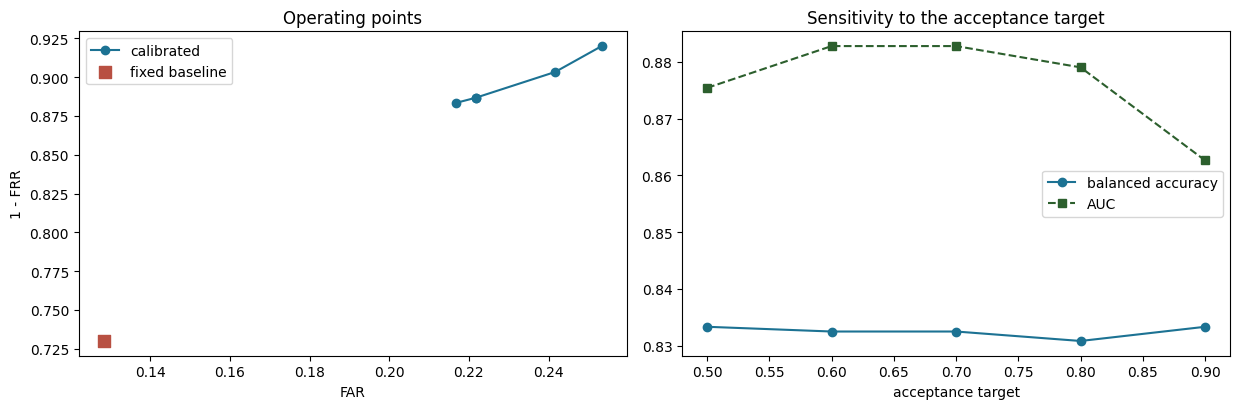

[timer] 8 sweep: 186.3s   (total 1701.3s)


In [13]:
SWEEP_TARGETS = (0.50, 0.60, 0.70, 0.80, 0.90)
arm = ("HOG","norm"); sweep = []
for t in SWEEP_TARGETS:
    cal = {}
    for wid in DEV:
        s = DS[arm][wid]; cs, _ = cohort_pool_sigs(arm[0], arm[1], wid)
        cal[wid] = calibrate_writer(s["W"], s["D"], s["idx"], cs, "target", target=t)
    params = {w: {"nu":cal[w]["nu"], "gamma":cal[w]["gamma"]} for w in DEV}
    _, ov = evaluate(arm, params, f"target={t}")
    sweep.append({"target":t, **{k: ov[k] for k in ("FRR","FAR","AUC","BalAcc","F1")}})
    print(f"  target {t:.2f}  FRR {ov['FRR']:.4f}  FAR {ov['FAR']:.4f}  "
          f"BalAcc {ov['BalAcc']:.4f}  AUC {ov['AUC']:.4f}", flush=True)

SW = pd.DataFrame(sweep); SW.to_csv(OUT_DIR/"operating_point_sweep.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax[0].plot(SW.FAR, 1-SW.FRR, "o-", color="#1C7293", label="calibrated")
fxp = RES[(RES.Arm=="HOG-norm")&(RES.Selection=="fixed")].iloc[0]
ax[0].scatter([fxp.FAR], [1-fxp.FRR], marker="s", s=80, color="#B85042", zorder=5, label="fixed baseline")
ax[0].set_xlabel("FAR"); ax[0].set_ylabel("1 - FRR"); ax[0].set_title("Operating points"); ax[0].legend()
ax[1].plot(SW.target, SW.BalAcc, "o-", color="#1C7293", label="balanced accuracy")
ax[1].plot(SW.target, SW.AUC, "s--", color="#2C5F2D", label="AUC")
ax[1].set_xlabel("acceptance target"); ax[1].set_title("Sensitivity to the acceptance target"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_DIR/"operating_points.png", dpi=130); plt.show()
mark("8 sweep")

## 9. Matched false-acceptance comparison

Mean metrics taken at different operating points are not directly comparable. The
comparison below applies a single additive offset to the pooled decision scores of
each condition, chosen so that the mean false acceptance rate equals that of the
fixed baseline, and then reports the corresponding false rejection rate.

This is a post-hoc comparison. The offset is determined using held-out forged
signatures and therefore does not describe a deployable operating point; its sole
purpose is to separate a genuine improvement in discrimination from a shift along
the existing trade-off curve.

In [14]:
def collect_scores(arm, params):
    g, f = {}, {}
    for wid in DEV:
        s = DS[arm][wid]
        pr = params[wid] if wid in params else params
        m, sc = fit_pairs(s["D"], pr["nu"], pr["gamma"])
        _, gs = _score_block(m, sc, s["Qg"]); _, fs = _score_block(m, sc, s["Qf"])
        g[wid], f[wid] = gs, fs
    return g, f

def rates_at_offset(g, f, off):
    frr = np.mean([np.mean((g[w] + off) < 0) for w in DEV])
    far = np.mean([np.mean((f[w] + off) >= 0) for w in DEV])
    return float(frr), float(far)

def frr_at_matched_far(g, f, target_far):
    """Largest offset whose mean FAR does not exceed `target_far`.

    Candidate offsets are taken from the observed forged scores, so the attainable
    FAR values are enumerated exactly rather than approached by bisection. Mean FAR
    is a step function of the offset, so an exact match is attainable only when the
    target lies on a step; the achieved value is returned so that any shortfall is
    visible. Where the reference FAR is zero the comparison is degenerate and the
    caller is expected to report it as such.
    """
    pooled = np.concatenate([f[w] for w in DEV])
    cands = np.unique(np.r_[-pooled - 1e-9, -pooled + 1e-9, 0.0])
    best = None
    for off in cands:
        frr, far = rates_at_offset(g, f, float(off))
        if far <= target_far + 1e-12 and (best is None or off > best[2]):
            best = (frr, far, float(off))
    if best is None:
        off = float(cands.min()); frr, far = rates_at_offset(g, f, off)
        return frr, far, off, False
    return best[0], best[1], best[2], True

arm = ("HOG","norm")
gB, fB = collect_scores(arm, PAIR_BASELINE)
frrB, farB = rates_at_offset(gB, fB, 0.0)
print("="*92); print("MATCHED-FAR COMPARISON -- primary arm (HOG, intensity-normalised)"); print("="*92)
print(f"  fixed baseline operating point: FRR {frrB:.4f}  FAR {farB:.4f}")
rows = [{"Selection":"fixed", "FRR":frrB, "FAR":farB, "offset":0.0}]
for crit in ("target","margin"):
    params = {w: {"nu":CAL[(arm,crit)][w]["nu"], "gamma":CAL[(arm,crit)][w]["gamma"]} for w in DEV}
    g, f = collect_scores(arm, params)
    frr0, far0 = rates_at_offset(g, f, 0.0)
    frrm, farm, off, ok = frr_at_matched_far(g, f, farB)
    rows.append({"Selection":crit, "FRR":frrm, "FAR":farm, "offset":off, "attained":ok})
    print(f"  {crit:7s}: native FRR {frr0:.4f} / FAR {far0:.4f}  ->  "
          f"at FAR {farm:.4f} (target {farB:.4f}): FRR {frrm:.4f}  offset {off:+.3f}"
          f"{'' if ok else '   [target unattainable]'}")
MF = pd.DataFrame(rows); MF.to_csv(OUT_DIR/"matched_far.csv", index=False)
if farB <= 1e-12:
    print("\n  The fixed baseline admits no false acceptances on this partition, so a")
    print("  matched-FAR comparison is degenerate: any offset that raises acceptance")
    print("  also raises FAR above the reference. Compare the native operating points")
    print("  and the operating-point curve in Section 8 instead.")
else:
    print(f"\n  FRR at matched FAR = {farB:.4f}:  fixed {rows[0]['FRR']:.4f}  ->  "
          f"margin {rows[-1]['FRR']:.4f}   ({rows[-1]['FRR']-rows[0]['FRR']:+.4f})")
mark("9 matched FAR")

MATCHED-FAR COMPARISON -- primary arm (HOG, intensity-normalised)
  fixed baseline operating point: FRR 0.3033  FAR 0.1217
  target : native FRR 0.1267 / FAR 0.2200  ->  at FAR 0.1217 (target 0.1217): FRR 0.3600  offset -0.015
  margin : native FRR 0.2067 / FAR 0.1833  ->  at FAR 0.1217 (target 0.1217): FRR 0.4133  offset -0.068

  FRR at matched FAR = 0.1217:  fixed 0.3033  ->  margin 0.4133   (+0.1100)
[timer] 9 matched FAR: 2.2s   (total 1703.4s)


## 10. Decision attribution

The verification decision is a function of a questioned signature and the twelve
enrolled signatures jointly, so an attribution map must be defined over that joint
quantity rather than over a single image. A square patch of the questioned
signature is occluded, the full feature path is recomputed on the occluded image,
the pair descriptor is rebuilt against every enrolled signature, and the mean
decision function is re-evaluated. The attribution assigned to a patch is the
resulting drop in score; patch values are accumulated onto a pixel grid, averaging
where patches overlap.

Recomputing the feature path rather than masking entries of an existing feature
vector is necessary for the gradient-based alternatives' absence to be meaningful:
occluding pixels alters the gradient structure of neighbouring cells, and zeroing
elements of a precomputed HOG vector would not correspond to any real image.

Gradient-based attribution methods are not applicable to this model. A one-class
support vector machine with a radial basis function kernel exposes no
differentiable path from output to input, so Integrated Gradients, DeepLIFT,
Grad-CAM and SHAP's gradient variants cannot be computed for it. Occlusion requires
only the ability to score an input.

**Faithfulness.** A deletion curve is computed by occluding patches in order of
descending attribution and recording the score after each step. A faithful map
causes the score to fall faster than occlusion in random order. The normalised area
under the deletion curve is reported against the mean of several random orderings.

**Saturation.** Attribution is defined only where the score is locally sensitive to
the input. A questioned signature lying far outside the boundary may be unaffected
by the occlusion of any single patch, in which case every patch records a zero drop
and no map exists. Such cases are reported as saturated rather than as maps of
uniform zero attribution, and are excluded from the faithfulness summary. This is a
property of the decision function rather than of the attribution method, and it
bounds the settings in which a sensitivity map can be displayed at all.

**Scope.** This component is evaluated as a score-sensitivity diagnostic. It is not
offered as a forensic explanation, and no comparison against examiner-marked
regions is attempted; recent work establishes that standard for gradient-based
attribution on this dataset using expert annotation, which is outside the scope of
this experiment.

Attribution for writer 3: 6 questioned signatures, patch 12, stride 6
  original_3_2.png             genuine score +0.0556  deletion AUC 0.810 vs random 0.422
  original_3_12.png            genuine score +0.3401  deletion AUC 0.662 vs random 0.415
  original_3_11.png            genuine score +0.1440  deletion AUC 0.808 vs random 0.463
  forgeries_3_9.png            forged  score -0.7894  deletion AUC 0.092 vs random 0.328
  forgeries_3_16.png           forged  score +0.5139  deletion AUC 0.316 vs random 0.394
  forgeries_3_18.png           forged  score +0.1154  deletion AUC 0.157 vs random 0.385

ATTRIBUTION FAITHFULNESS
              file  genuine  base_score  saturated  max_abs_drop  deletion_auc_attr  deletion_auc_random  faithfulness_gain  attr_mass_on_ink  ink_fraction
  original_3_2.png        1      0.0556      False        0.2026             0.8099               0.4217            -0.3881            0.1634        0.0594
 original_3_12.png        1      0.3401      False        

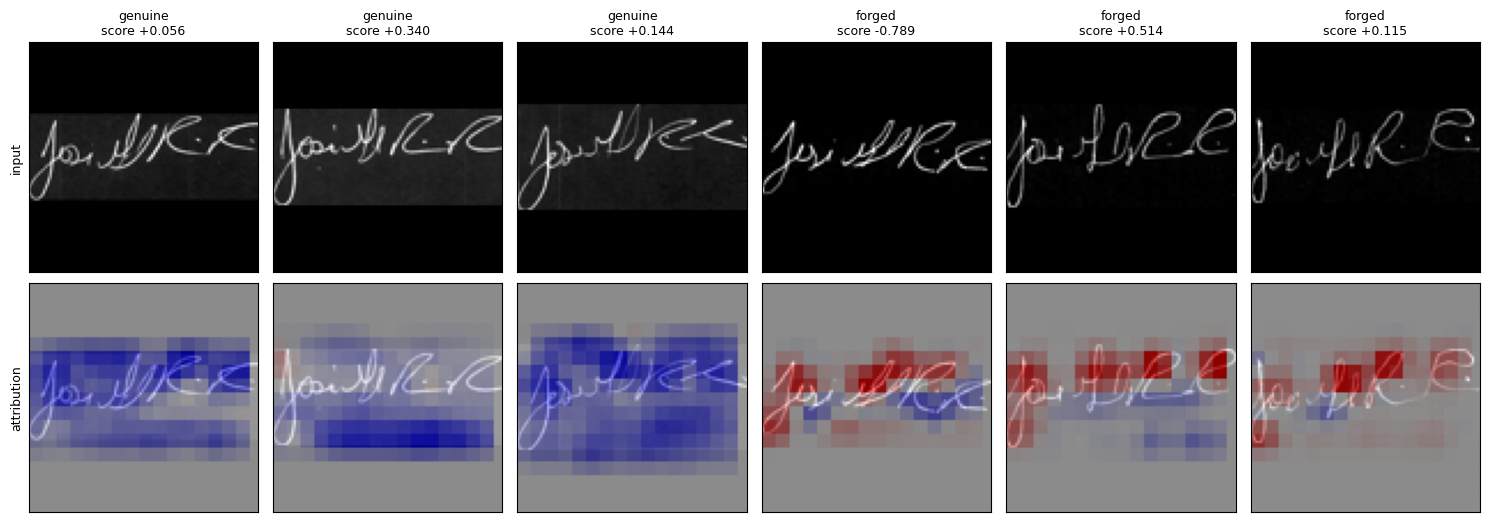

[timer] 10 attribution: 40.2s   (total 1743.7s)


In [15]:
ATTR_REP, ATTR_COND = "HOG", "norm"
attr_fn = FEATURE_FNS[ATTR_REP]; attr_scaler = SC[(ATTR_REP, ATTR_COND)]

def _image(path):
    return intensity_normalise(preprocess_gray(path))

def _pair_score(model, pair_sc, img, W):
    v = attr_scaler.transform(attr_fn(img).reshape(1,-1))[0]
    Q = pair_sc.transform(np.array([pair_descriptor(v, t) for t in W]))
    return float(model.decision_function(Q).mean())

def _positions(H, W_, patch, stride):
    return [(t,l) for t in range(0, max(H-patch,0)+1, stride)
                  for l in range(0, max(W_-patch,0)+1, stride)]

def occlusion_map(model, pair_sc, img, W, patch=ATTR_PATCH, stride=ATTR_STRIDE):
    H, W_ = img.shape
    base = _pair_score(model, pair_sc, img, W)
    pos = _positions(H, W_, patch, stride)
    acc = np.zeros((H,W_)); cnt = np.zeros((H,W_)); drops = []
    for (t,l) in pos:
        o = img.copy(); o[t:t+patch, l:l+patch] = 0.0
        d = base - _pair_score(model, pair_sc, o, W)
        drops.append(d)
        acc[t:t+patch, l:l+patch] += d; cnt[t:t+patch, l:l+patch] += 1
    cnt[cnt==0] = 1
    return acc/cnt, base, pos, np.array(drops)

def deletion_curve(model, pair_sc, img, W, pos, order, steps=DELETION_STEPS, patch=ATTR_PATCH):
    base = _pair_score(model, pair_sc, img, W)
    ks = np.linspace(0, len(order), steps+1)[1:].astype(int)
    o = img.copy(); scores = [base]; prev = 0
    for k in ks:
        for j in order[prev:k]:
            t,l = pos[j]; o[t:t+patch, l:l+patch] = 0.0
        scores.append(_pair_score(model, pair_sc, o, W)); prev = k
    s = np.array(scores)
    rng_ = (s[0] - s.min()) if (s[0]-s.min()) > 1e-12 else 1.0
    return s, float(_trapz((s - s.min())/rng_, dx=1.0/steps))

params_attr = {w: {"nu":CAL[((ATTR_REP,ATTR_COND),"margin")][w]["nu"],
                   "gamma":CAL[((ATTR_REP,ATTR_COND),"margin")][w]["gamma"]} for w in DEV}
wid = DEV[0]; s = DS[(ATTR_REP,ATTR_COND)][wid]
m_a, sc_a = fit_pairs(s["D"], params_attr[wid]["nu"], params_attr[wid]["gamma"])
Wenr = s["W"]

sel = ([(p,1) for p in writer_splits[wid]["test_genuine"][:ATTR_N_GENUINE]] +
       [(p,0) for p in writer_splits[wid]["test_forged"][:ATTR_N_FORGED]])
print(f"Attribution for writer {wid}: {len(sel)} questioned signatures, "
      f"patch {ATTR_PATCH}, stride {ATTR_STRIDE}", flush=True)

maps, faith = [], []
for p, lab in sel:
    img = _image(p)
    hm, base, pos, drops = occlusion_map(m_a, sc_a, img, Wenr)
    order = np.argsort(-drops)
    _, auc_attr = deletion_curve(m_a, sc_a, img, Wenr, pos, order)
    rnd = []
    for r in range(DELETION_RANDOM_REPEATS):
        ro = np.random.default_rng(100+r).permutation(len(pos))
        _, a = deletion_curve(m_a, sc_a, img, Wenr, pos, ro); rnd.append(a)
    ink = img > INK_THRESH
    saturated = float(np.abs(drops).max()) < SATURATION_TOL
    on_ink = (float("nan") if saturated else
              float(np.abs(hm)[ink].sum()/max(np.abs(hm).sum(), 1e-12)))
    maps.append((p.name, lab, img, hm, base, saturated))
    faith.append({"file":p.name, "genuine":lab, "base_score":base, "saturated":saturated,
                  "max_abs_drop":float(np.abs(drops).max()),
                  "deletion_auc_attr":float("nan") if saturated else auc_attr,
                  "deletion_auc_random":float("nan") if saturated else float(np.mean(rnd)),
                  "faithfulness_gain":float("nan") if saturated else float(np.mean(rnd))-auc_attr,
                  "attr_mass_on_ink":on_ink, "ink_fraction":float(ink.mean())})
    tag = "genuine" if lab else "forged"
    if saturated:
        print(f"  {p.name:28s} {tag:7s} score {base:+.4f}  "
              f"saturated (max |drop| {np.abs(drops).max():.2e}) -- no local sensitivity", flush=True)
    else:
        print(f"  {p.name:28s} {tag:7s} score {base:+.4f}  "
              f"deletion AUC {auc_attr:.3f} vs random {np.mean(rnd):.3f}", flush=True)

FA = pd.DataFrame(faith); FA.to_csv(OUT_DIR/"attribution_faithfulness.csv", index=False)
print("\n" + "="*92); print("ATTRIBUTION FAITHFULNESS"); print("="*92)
print(FA.round(4).to_string(index=False))

ok = FA[~FA.saturated]
print(f"\n  informative maps: {len(ok)}/{len(FA)}   "
      f"saturated: {int(FA.saturated.sum())} "
      f"({int(FA[FA.saturated].genuine.eq(0).sum())} forged, "
      f"{int(FA[FA.saturated].genuine.eq(1).sum())} genuine)")
if len(ok):
    print(f"  mean faithfulness gain over random ordering: {ok.faithfulness_gain.mean():+.4f}  "
          f"({int((ok.faithfulness_gain > 0).sum())}/{len(ok)} better than random)")
    print(f"  mean attribution mass on ink: {ok.attr_mass_on_ink.mean():.1%}  "
          f"(ink occupies {ok.ink_fraction.mean():.1%} of pixels)")
    print(f"  concentration ratio: "
          f"{ok.attr_mass_on_ink.mean()/max(ok.ink_fraction.mean(),1e-9):.2f}x")
else:
    print("  No informative map was produced: every attributed signature sits far enough")
    print("  from the boundary that occluding any single patch leaves the decision")
    print("  unchanged. Attribution is only defined where the score is locally sensitive.")

fig, axes = plt.subplots(2, len(maps), figsize=(2.5*len(maps), 5.4), squeeze=False)
for j, (name, lab, img, hm, base, sat) in enumerate(maps):
    axes[0][j].imshow(img, cmap="gray"); axes[0][j].set_title(
        f"{'genuine' if lab else 'forged'}\nscore {base:+.3f}"
        + ("\n(saturated)" if sat else ""), fontsize=9)
    v = np.max(np.abs(hm)) or 1.0
    axes[1][j].imshow(img, cmap="gray"); axes[1][j].imshow(hm, cmap="bwr", vmin=-v, vmax=v, alpha=0.55)
    for a in (axes[0][j], axes[1][j]): a.set_xticks([]); a.set_yticks([])
axes[0][0].set_ylabel("input", fontsize=9); axes[1][0].set_ylabel("attribution", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR/"attribution_maps.png", dpi=130); plt.show()
mark("10 attribution")

## 11. Summary and runtime

In [16]:
print("="*100); print("SUMMARY -- 25 development writers, intensity-normalised protocol"); print("="*100)
print(RES.round(4).to_string(index=False))
print("\n  Acquisition-cue contribution at the fixed baseline:")
for rep in ("RAW","HOG"):
    gl = BASE[(BASE.Rep==rep)&(BASE.Condition=="gray")].iloc[0]
    nm = BASE[(BASE.Rep==rep)&(BASE.Condition=="norm")].iloc[0]
    print(f"    {rep}: AUC {gl.AUC:.4f} (gray) -> {nm.AUC:.4f} (normalised)   {nm.AUC-gl.AUC:+.4f}")
print(f"\n  Strongest residual image statistic after normalisation: "
      f"{cue['norm'].idxmax()} at AUC {cue['norm'].max():.4f}")
print("  Matched-FAR comparison: see Section 9 "
      f"(reference FAR {MF.iloc[0].FAR:.4f}" + ("; degenerate" if MF.iloc[0].FAR <= 1e-12 else "") + ")")
print(f"  Attribution: {int((~FA.saturated).sum())}/{len(FA)} maps informative, "
      f"mean faithfulness gain {FA[~FA.saturated].faithfulness_gain.mean():+.4f}"
      if (~FA.saturated).any() else "  Attribution: no informative map (all saturated)")
print(f"\n  Confirmation writers ({len(CONFIRM)}) remain unevaluated.")

total = time.time()-NB_T0; h, rem = divmod(total, 3600); m_, s_ = divmod(rem, 60)
print("\n" + "="*70); print("RUNTIME"); print("="*70)
print(f"  Google Colaboratory, High-RAM, Python {sys.version.split()[0]}, CPU")
print(f"  OneClassSVM is CPU-only; no GPU or TPU backend exists for this estimator.")
print("-"*70)
for k, v in SECTION_TIMES.items():
    if k == "_last": continue
    print(f"  {k:28s} {v:8.1f}s  ({v/60:5.2f} min)")
print("-"*70)
print(f"  TOTAL {int(h)}h {int(m_)}m {int(s_)}s  ({total/60:.1f} min)")
pd.DataFrame([{"section":k,"seconds":v} for k,v in SECTION_TIMES.items() if k!="_last"]) \
  .to_csv(OUT_DIR/"v5_runtime.csv", index=False)
print(f"\n  Artifacts: {OUT_DIR}")
for fp in sorted(OUT_DIR.glob("*")): print("   ", fp.name)

SUMMARY -- 25 development writers, intensity-normalised protocol
     Arm Selection    FRR    FAR  Accuracy     F1    AUC  BalAcc  median_FRR
HOG-norm     fixed 0.2700 0.1283    0.8244 0.7582 0.8868  0.8008      0.2500
HOG-norm    target 0.1133 0.2217    0.8144 0.8063 0.8828  0.8325      0.0833
HOG-norm    margin 0.1400 0.1883    0.8278 0.8109 0.8717  0.8358      0.1667
RAW-norm     fixed 0.3467 0.0100    0.8778 0.7662 0.9701  0.8217      0.3333
RAW-norm    target 0.1733 0.0400    0.9156 0.8771 0.9547  0.8933      0.1667
RAW-norm    margin 0.1833 0.0483    0.9067 0.8646 0.9585  0.8842      0.1667

  Acquisition-cue contribution at the fixed baseline:
    RAW: AUC 0.9762 (gray) -> 0.9701 (normalised)   -0.0061
    HOG: AUC 0.8871 (gray) -> 0.8868 (normalised)   -0.0003

  Strongest residual image statistic after normalisation: fill_density at AUC 1.0000
  Matched-FAR comparison: see Section 9 (reference FAR 0.1217)
  Attribution: 6/6 maps informative, mean faithfulness gain -0.0731

  C